# 📊 Notebook 1: Khám phá Dữ liệu (EDA)
## Đề tài: Phân tích và Dự đoán Khách hàng Rời bỏ (Customer Churn Prediction)
**Dataset:** Telco Customer Churn – [Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)

---
### Mục tiêu EDA:
1. Hiểu cấu trúc và kiểu dữ liệu của từng cột
2. Phát hiện giá trị thiếu (missing values)
3. Phân tích phân phối từng feature
4. Tìm mối liên hệ giữa các features với biến mục tiêu **Churn**
5. Phát hiện bất thường / outliers

In [1]:
# ============================================================
# IMPORT THƯ VIỆN
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')
sns.set_palette('husl')

print('✅ Thư viện import thành công!')
print(f'   pandas  : {pd.__version__}')
print(f'   numpy   : {np.__version__}')
print(f'   seaborn : {sns.__version__}')

✅ Thư viện import thành công!
   pandas  : 3.0.5
   numpy   : 2.5.3
   seaborn : 0.13.2


---
## 1. Tải Dữ liệu

In [2]:
# ============================================================
# TẢI DỮ LIỆU
# Đặt file CSV cùng thư mục với notebook này
    data_path = '../data/raw/telco_churn.csv' if os.path.exists('../data/raw/telco_churn.csv') else 'data/raw/telco_churn.csv'
    df = pd.read_csv(data_path)
# ============================================================
try:
    data_path = '../data/raw/telco_churn.csv' if os.path.exists('../data/raw/telco_churn.csv') else 'data/raw/telco_churn.csv'
    df = pd.read_csv(data_path)
    print(f'✅ Tải dữ liệu thành công!')
    print(f'   Số hàng : {df.shape[0]:,}')
    print(f'   Số cột  : {df.shape[1]}')
except FileNotFoundError:
    print('❌ Không tìm thấy file. Hãy tải dataset từ:')
    print('   https://www.kaggle.com/datasets/blastchar/telco-customer-churn')
    print('   Và đặt file CSV vào thư mục CustomerChurnPrediction/')

✅ Tải dữ liệu thành công!
   Số hàng : 7,043
   Số cột  : 21


In [3]:
# Xem 5 hàng đầu
print('📋 5 hàng đầu của dataset:')
df.head()

📋 5 hàng đầu của dataset:


In [4]:
# Xem 5 hàng cuối
print('📋 5 hàng cuối của dataset:')
df.tail()

📋 5 hàng cuối của dataset:


---
## 2. Thông tin Tổng quan Dataset

In [5]:
# ============================================================
# THÔNG TIN CỘT VÀ KIỂU DỮ LIỆU
# ============================================================
print('📊 Thông tin dataset:')
df.info()

📊 Thông tin dataset:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null 

In [6]:
# ============================================================
# THỐNG KÊ MÔ TẢ
# ============================================================
print('📊 Thống kê mô tả các cột số:')
df.describe()

📊 Thống kê mô tả các cột số:


In [7]:
print('📊 Thống kê mô tả các cột phân loại:')
df.describe(include='object')

📊 Thống kê mô tả các cột phân loại:


---
## 3. Phân tích Giá trị Thiếu (Missing Values)

> ⚠️ **Quan trọng:** Cột `TotalCharges` được lưu dạng **string** trong file CSV.  
> Một số ô có giá trị khoảng trắng `" "` → khi convert sang số sẽ thành `NaN`.  
> Đây là vấn đề **data cleaning** chính của đề tài này!

In [8]:
# ============================================================
# KIỂM TRA MISSING VALUES TRỰC TIẾP
# ============================================================
print('=== KIỂM TRA MISSING VALUES (NaN) ===')
missing_direct = df.isnull().sum()
print(missing_direct[missing_direct > 0])
print(f'\n→ Tổng NaN trực tiếp: {missing_direct.sum()}')

=== KIỂM TRA MISSING VALUES (NaN) ===
Series([], dtype: int64)

→ Tổng NaN trực tiếp: 0


In [9]:
# ============================================================
# PHÁT HIỆN GIÁ TRỊ KHOẢNG TRẮNG TRONG TotalCharges
# ============================================================
print('=== KIỂM TRA CỘT TotalCharges ===')
print(f'Kiểu dữ liệu hiện tại: {df["TotalCharges"].dtype}')
print(f'\nSố giá trị khoảng trắng " ": {(df["TotalCharges"].str.strip() == "").sum()}')

# Convert thử và đếm NaN
tc_numeric = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(f'Số NaN sau khi convert sang numeric: {tc_numeric.isnull().sum()}')

print('\n--- Các hàng có TotalCharges là khoảng trắng ---')
mask_blank = df['TotalCharges'].str.strip() == ''
df[mask_blank][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

=== KIỂM TRA CỘT TotalCharges ===
Kiểu dữ liệu hiện tại: str

Số giá trị khoảng trắng " ": 11
Số NaN sau khi convert sang numeric: 11

--- Các hàng có TotalCharges là khoảng trắng ---


In [10]:
# ============================================================
# PHÂN TÍCH LOẠI MISSING DATA
# ============================================================
print('=== PHÂN TÍCH LOẠI MISSING DATA: MAR / MCAR / MNAR ===')
print()

tc_null_rows = df[tc_numeric.isnull()]
tc_not_null_rows = df[~tc_numeric.isnull()]

print(f'Số hàng bị thiếu TotalCharges : {len(tc_null_rows)}')
print(f'Tenure trung bình của hàng thiếu: {tc_null_rows["tenure"].mean():.2f}')
print(f'Tenure trung bình của hàng không thiếu: {tc_not_null_rows["tenure"].mean():.2f}')
print()
print('→ Tất cả hàng thiếu TotalCharges có tenure = 0 (khách hàng mới)')
print('→ KẾT LUẬN: Loại Missing Data là MAR (Missing At Random)')
print('   Lý do: Việc TotalCharges bị thiếu PHỤ THUỘC vào biến')
print('   "tenure" (có thể quan sát được), KHÔNG phải ngẫu nhiên')
print('   hoàn toàn (MCAR) và cũng không phải do bản thân')
print('   giá trị TotalCharges quyết định (MNAR).')

=== PHÂN TÍCH LOẠI MISSING DATA: MAR / MCAR / MNAR ===

Số hàng bị thiếu TotalCharges : 11
Tenure trung bình của hàng thiếu: 0.00
Tenure trung bình của hàng không thiếu: 32.42

→ Tất cả hàng thiếu TotalCharges có tenure = 0 (khách hàng mới)
→ KẾT LUẬN: Loại Missing Data là MAR (Missing At Random)
   Lý do: Việc TotalCharges bị thiếu PHỤ THUỘC vào biến
   "tenure" (có thể quan sát được), KHÔNG phải ngẫu nhiên
   hoàn toàn (MCAR) và cũng không phải do bản thân
   giá trị TotalCharges quyết định (MNAR).


✅ Biểu đồ đã lưu: plots/01_missing_values.png


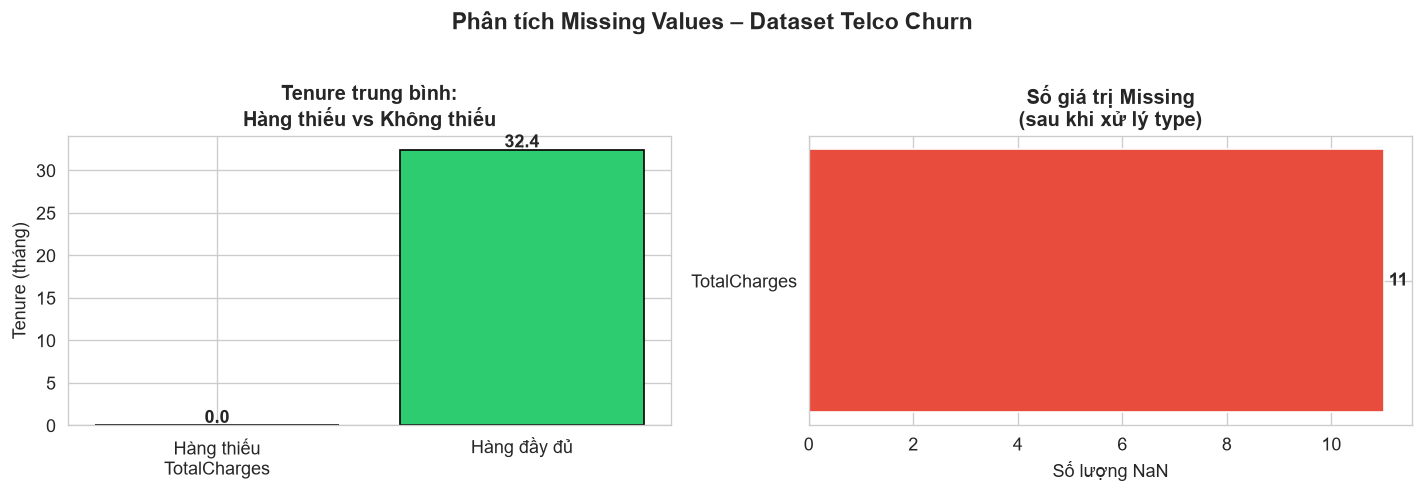

In [11]:
# Visualize missing pattern
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Biểu đồ tenure so sánh
axes[0].bar(['Hàng thiếu\nTotalCharges', 'Hàng đầy đủ'], 
             [tc_null_rows['tenure'].mean(), tc_not_null_rows['tenure'].mean()],
             color=['#e74c3c', '#2ecc71'], edgecolor='black')
axes[0].set_title('Tenure trung bình:\nHàng thiếu vs Không thiếu', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Tenure (tháng)')
for bar, val in zip(axes[0].patches, 
                    [tc_null_rows['tenure'].mean(), tc_not_null_rows['tenure'].mean()]):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                f'{val:.1f}', ha='center', fontweight='bold')

# Missing value heatmap
missing_df = pd.DataFrame({
    'Cột': df.columns,
    'Missing (trực tiếp)': df.isnull().sum().values,
    'Missing (sau convert)': [tc_numeric.isnull().sum() if c == 'TotalCharges' else df[c].isnull().sum() for c in df.columns]
})
missing_df = missing_df[missing_df['Missing (sau convert)'] > 0]
axes[1].barh(missing_df['Cột'], missing_df['Missing (sau convert)'], color='#e74c3c')
axes[1].set_title('Số giá trị Missing\n(sau khi xử lý type)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Số lượng NaN')
for i, v in enumerate(missing_df['Missing (sau convert)']):
    axes[1].text(v + 0.1, i, str(v), va='center', fontweight='bold')

plt.suptitle('Phân tích Missing Values – Dataset Telco Churn', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../reports/figures/01_missing_values.png', bbox_inches='tight', dpi=150)
plt.show()
print('✅ Biểu đồ đã lưu: ../reports/figures/01_missing_values.png')

---
## 4. Phân tích Biến Mục tiêu: Churn

=== PHÂN BỐ BIẾN MỤC TIÊU CHURN ===
   No: 5,174 (73.5%)
   Yes: 1,869 (26.5%)

⚠️  CLASS IMBALANCE: Tỉ lệ No:Yes ≈ 73:27
   → Cần dùng class_weight="balanced" khi train model
   → Không dùng Accuracy làm metric chính!
   → Dùng ROC-AUC + F1-Score (Recall ưu tiên)


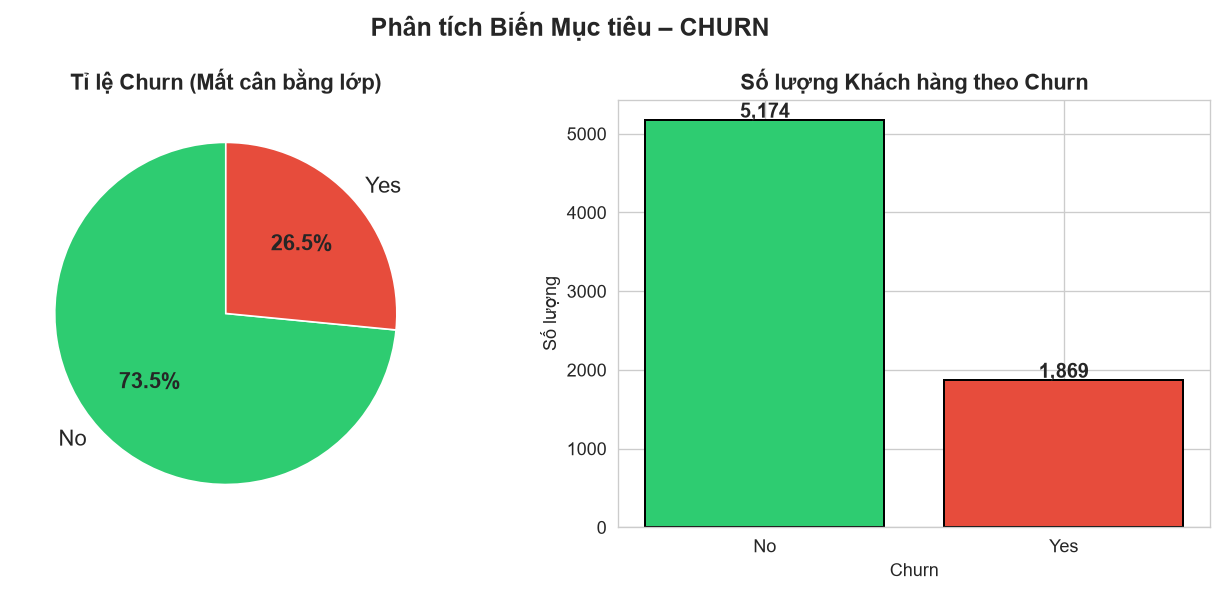

In [12]:
# ============================================================
# PHÂN BỐ BIẾN MỤC TIÊU CHURN
# ============================================================
churn_counts = df['Churn'].value_counts()
churn_pct = df['Churn'].value_counts(normalize=True) * 100

print('=== PHÂN BỐ BIẾN MỤC TIÊU CHURN ===')
for label in churn_counts.index:
    print(f'   {label}: {churn_counts[label]:,} ({churn_pct[label]:.1f}%)')

print()
print('⚠️  CLASS IMBALANCE: Tỉ lệ No:Yes ≈ 73:27')
print('   → Cần dùng class_weight="balanced" khi train model')
print('   → Không dùng Accuracy làm metric chính!')
print('   → Dùng ROC-AUC + F1-Score (Recall ưu tiên)')

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

# Pie chart
colors = ['#2ecc71', '#e74c3c']
wedges, texts, autotexts = axes[0].pie(
    churn_counts, labels=churn_counts.index,
    autopct='%1.1f%%', colors=colors, startangle=90,
    textprops={'fontsize': 13})
for at in autotexts:
    at.set_fontweight('bold')
    at.set_fontsize(13)
axes[0].set_title('Tỉ lệ Churn (Mất cân bằng lớp)', fontsize=13, fontweight='bold')

# Bar chart
bars = axes[1].bar(churn_counts.index, churn_counts.values, 
                   color=colors, edgecolor='black', linewidth=1.2)
axes[1].set_title('Số lượng Khách hàng theo Churn', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Số lượng')
axes[1].set_xlabel('Churn')
for bar, val in zip(bars, churn_counts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
                f'{val:,}', ha='center', fontsize=12, fontweight='bold')

plt.suptitle('Phân tích Biến Mục tiêu – CHURN', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/02_churn_distribution.png', bbox_inches='tight', dpi=150)
plt.show()

---
## 5. Phân tích Biến Số (Numeric Features)

=== THỐNG KÊ THEO CHURN ===

tenure:
        count   mean    std  min   25%   50%   75%   max
Churn                                                   
No     5174.0  37.57  24.11  0.0  15.0  38.0  61.0  72.0
Yes    1869.0  17.98  19.53  1.0   2.0  10.0  29.0  72.0

MonthlyCharges:
        count   mean    std    min    25%    50%   75%     max
Churn                                                         
No     5174.0  61.27  31.09  18.25  25.10  64.43  88.4  118.75
Yes    1869.0  74.44  24.67  18.85  56.15  79.65  94.2  118.35

TotalCharges:
        count    mean      std    min    25%      50%      75%      max
Churn                                                                  
No     5174.0  2550.0  2329.86  18.80  572.9  1679.52  4262.85  8672.45
Yes    1869.0  1531.8  1890.82  18.85  134.5   703.55  2331.30  8684.80


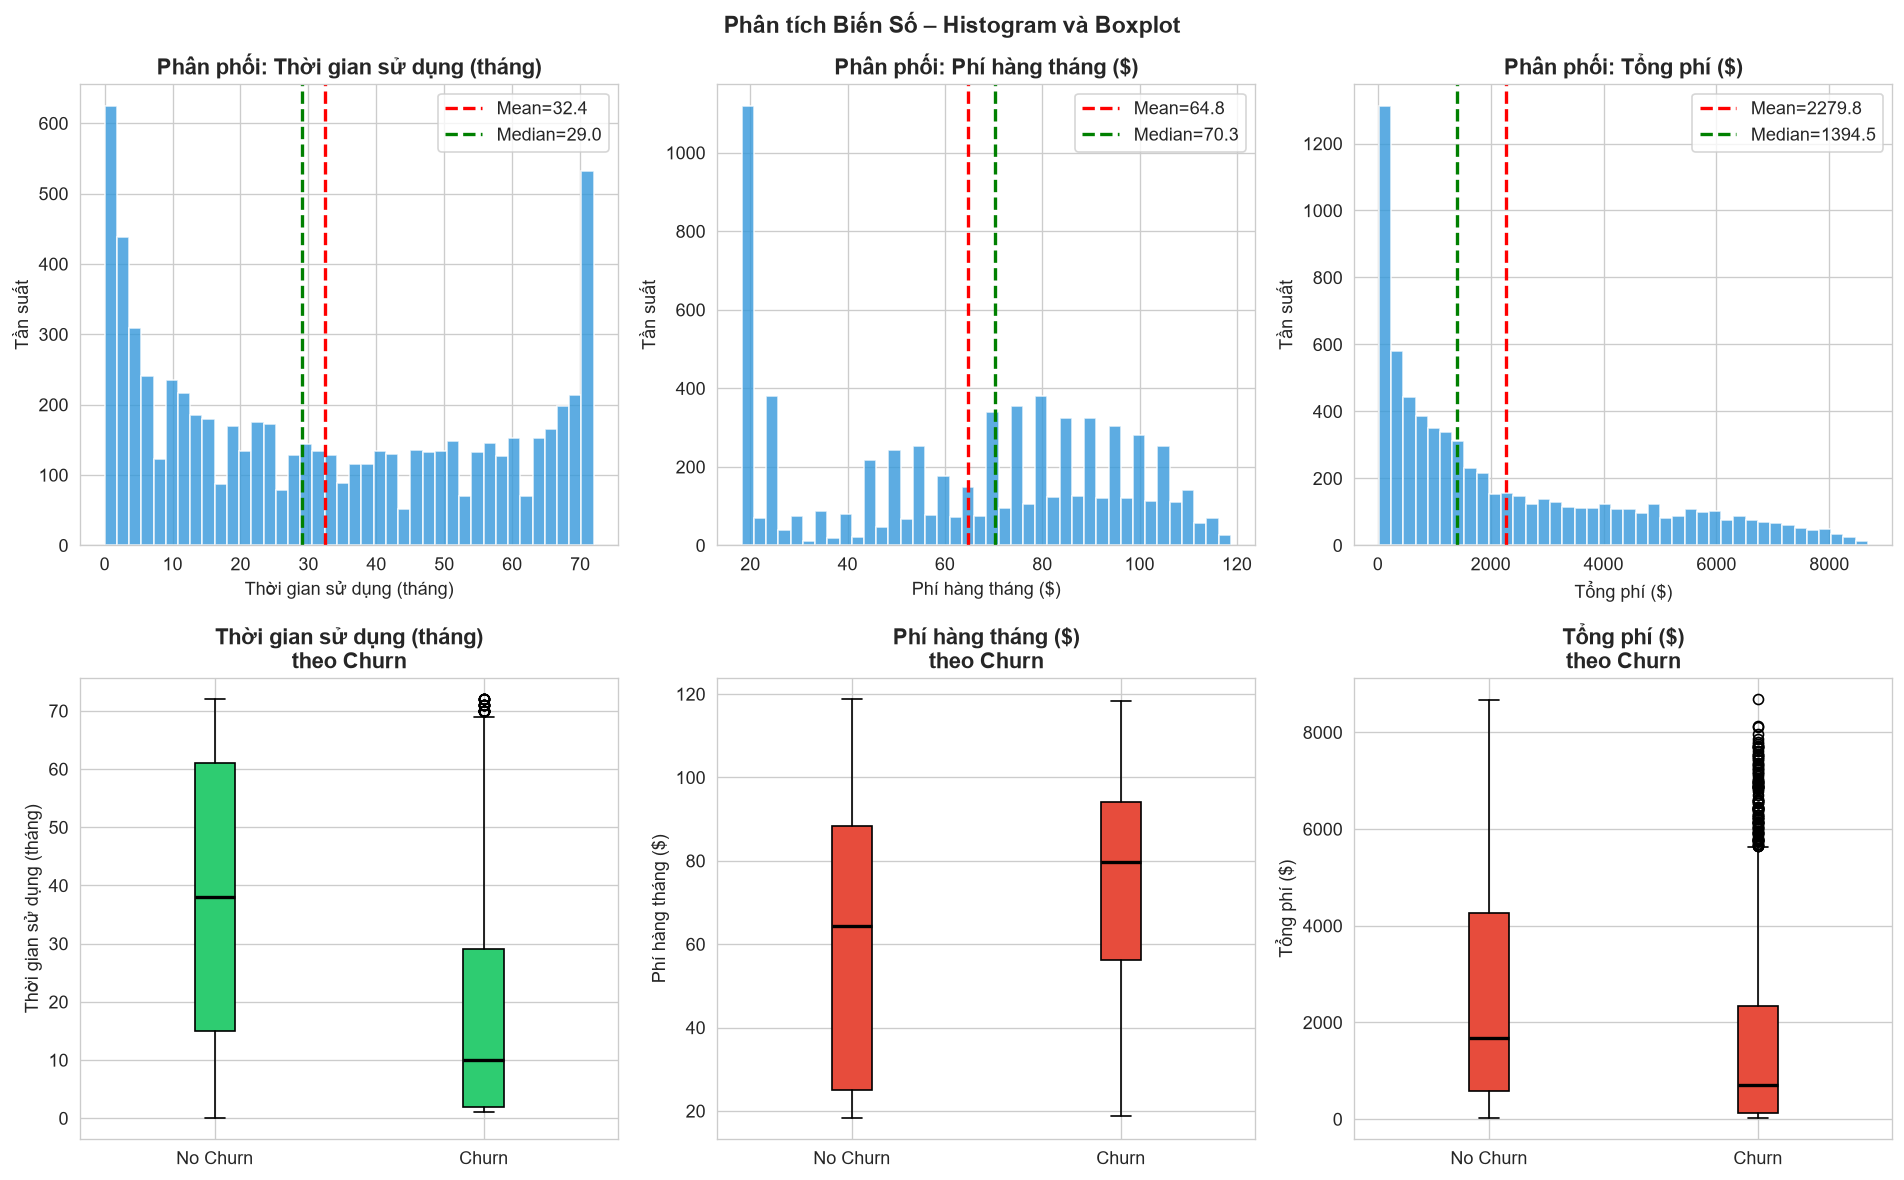

In [13]:
# ============================================================
# PHÂN BỐ CÁC BIẾN SỐ: tenure, MonthlyCharges, TotalCharges
# ============================================================
# Dùng bản copy đã convert TotalCharges sang numeric
df_temp = df.copy()
df_temp['TotalCharges'] = pd.to_numeric(df_temp['TotalCharges'], errors='coerce')
df_temp['TotalCharges'] = df_temp['TotalCharges'].fillna(df_temp['MonthlyCharges'])

numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
col_labels = ['Thời gian sử dụng (tháng)', 'Phí hàng tháng ($)', 'Tổng phí ($)']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for i, (col, label) in enumerate(zip(numeric_cols, col_labels)):
    # Hàng 1: Histogram tổng
    axes[0, i].hist(df_temp[col], bins=40, color='#3498db', edgecolor='white', alpha=0.8)
    axes[0, i].axvline(df_temp[col].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean={df_temp[col].mean():.1f}')
    axes[0, i].axvline(df_temp[col].median(), color='green', linestyle='--', linewidth=2, label=f'Median={df_temp[col].median():.1f}')
    axes[0, i].set_title(f'Phân phối: {label}', fontweight='bold')
    axes[0, i].set_xlabel(label)
    axes[0, i].set_ylabel('Tần suất')
    axes[0, i].legend()
    
    # Hàng 2: Box plot theo Churn
    churn_no = df_temp[df_temp['Churn'] == 'No'][col]
    churn_yes = df_temp[df_temp['Churn'] == 'Yes'][col]
    axes[1, i].boxplot([churn_no, churn_yes], tick_labels=['No Churn', 'Churn'],
                        patch_artist=True,
                        boxprops=dict(facecolor='#2ecc71' if i == 0 else '#e74c3c'),
                        medianprops=dict(color='black', linewidth=2))
    axes[1, i].set_title(f'{label}\ntheo Churn', fontweight='bold')
    axes[1, i].set_ylabel(label)

plt.suptitle('Phân tích Biến Số – Histogram và Boxplot', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/03_numeric_distributions.png', bbox_inches='tight', dpi=150)
plt.show()

# In thống kê
print('=== THỐNG KÊ THEO CHURN ===')
for col in numeric_cols:
    print(f'\n{col}:')
    print(df_temp.groupby('Churn')[col].describe().round(2))

---
## 6. Phân tích Biến Phân loại (Categorical Features) theo Churn

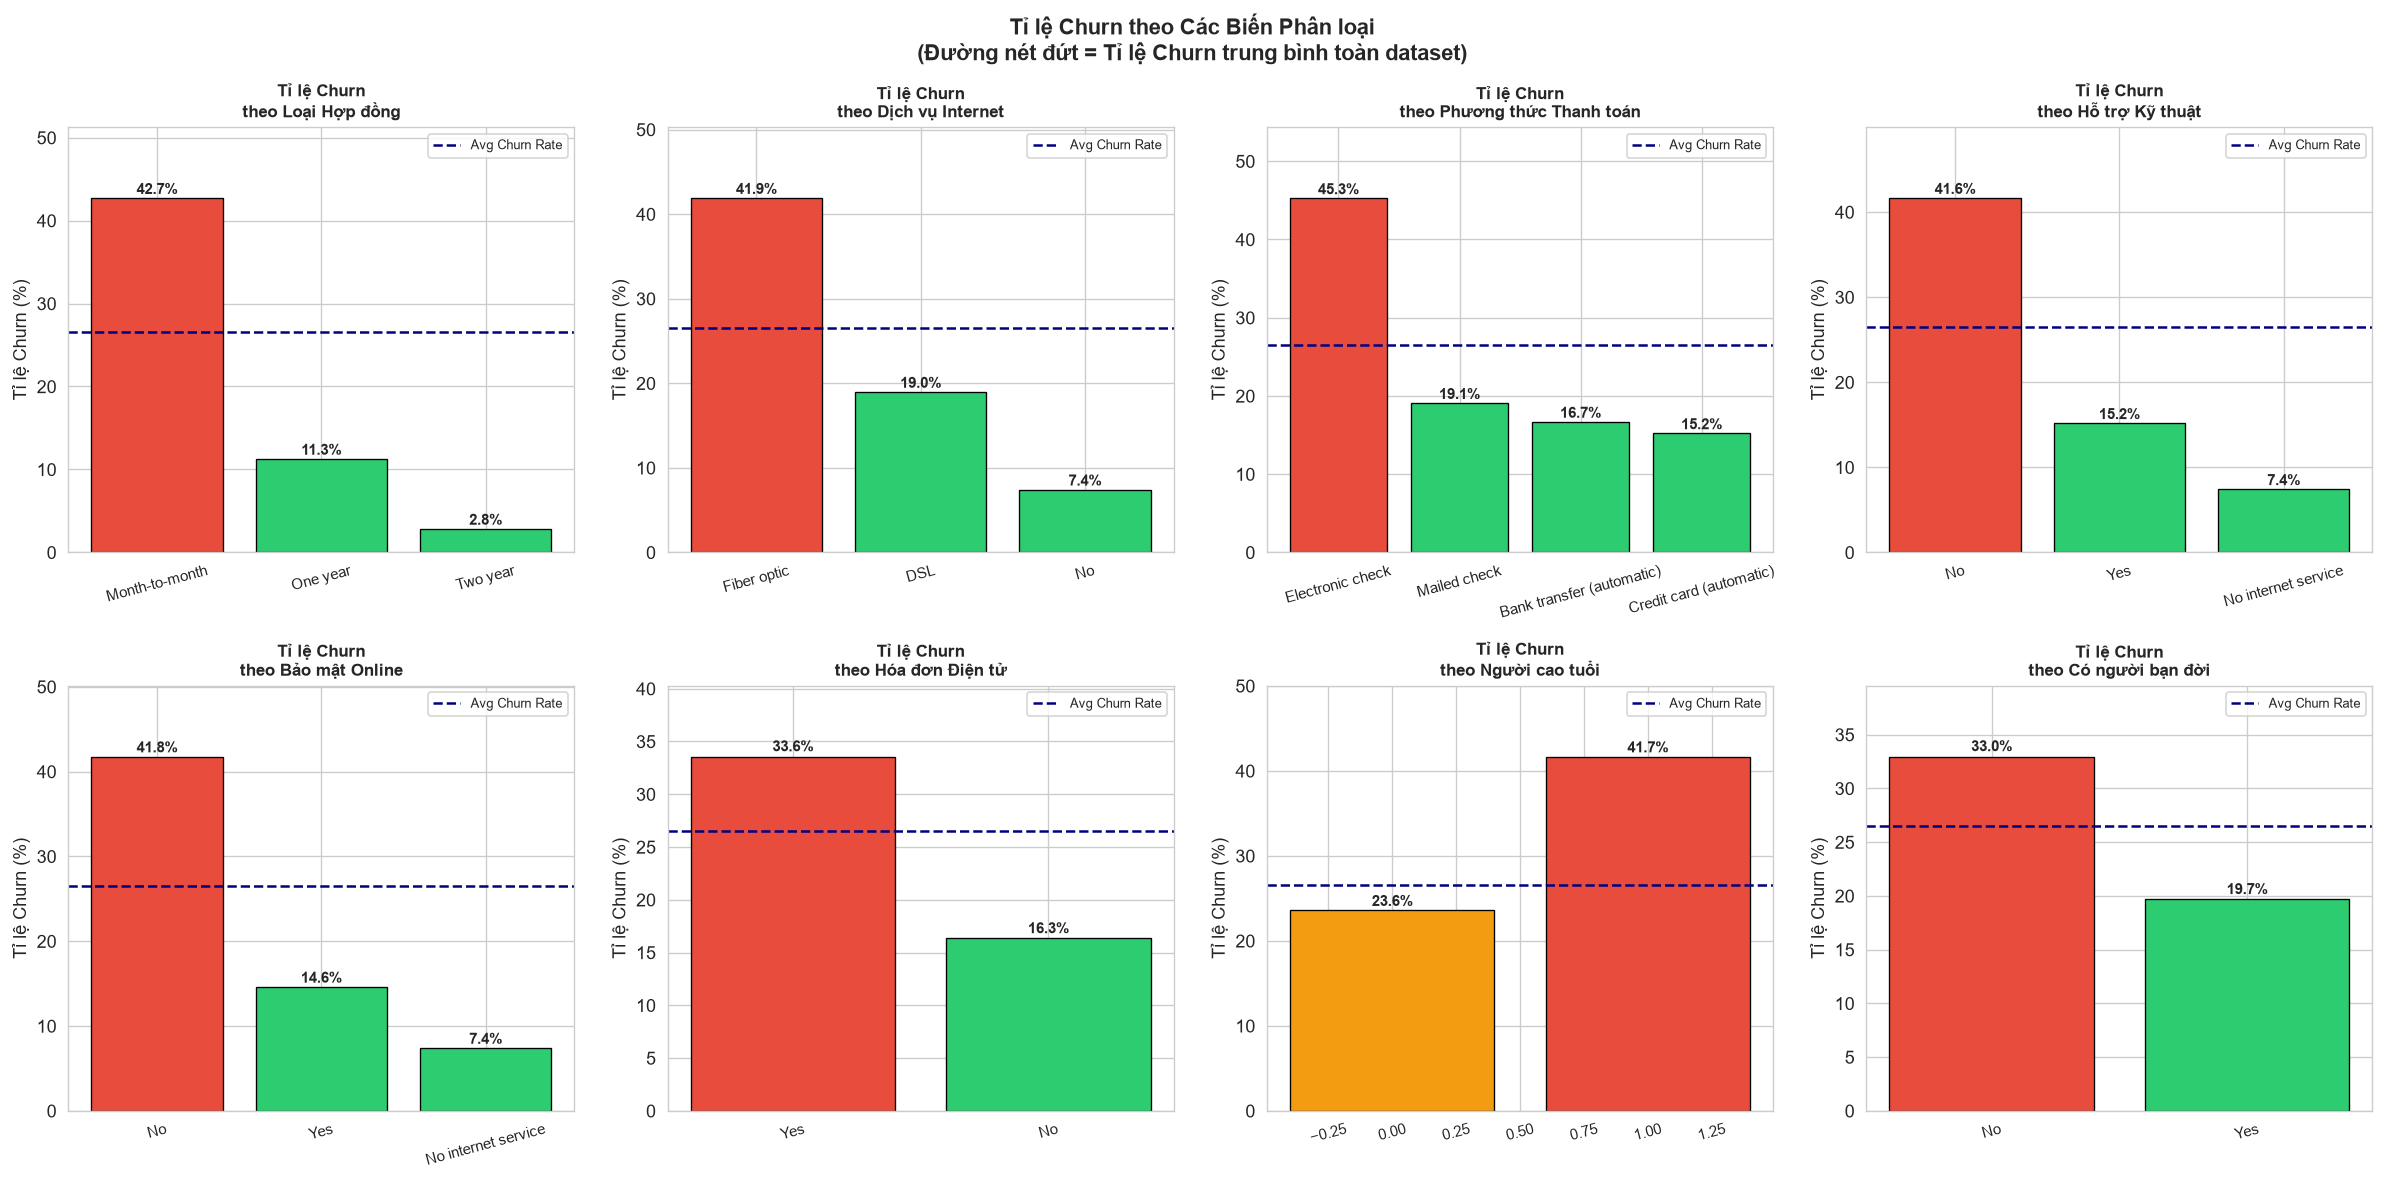

In [14]:
# ============================================================
# TỈ LỆ CHURN THEO CÁC BIẾN PHÂN LOẠI QUAN TRỌNG
# ============================================================
import matplotlib.gridspec as gridspec

cat_features = [
    ('Contract', 'Loại Hợp đồng'),
    ('InternetService', 'Dịch vụ Internet'),
    ('PaymentMethod', 'Phương thức Thanh toán'),
    ('TechSupport', 'Hỗ trợ Kỹ thuật'),
    ('OnlineSecurity', 'Bảo mật Online'),
    ('PaperlessBilling', 'Hóa đơn Điện tử'),
    ('SeniorCitizen', 'Người cao tuổi'),
    ('Partner', 'Có người bạn đời'),
]

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, (col, title) in enumerate(cat_features):
    # Tính tỉ lệ churn theo từng category
    churn_rate = df.groupby(col)['Churn'].apply(
        lambda x: (x == 'Yes').sum() / len(x) * 100
    ).sort_values(ascending=False)
    
    colors_bar = ['#e74c3c' if v > 30 else '#f39c12' if v > 20 else '#2ecc71' for v in churn_rate.values]
    bars = axes[i].bar(churn_rate.index, churn_rate.values, color=colors_bar, edgecolor='black', linewidth=0.8)
    axes[i].set_title(f'Tỉ lệ Churn\ntheo {title}', fontweight='bold', fontsize=10)
    axes[i].set_ylabel('Tỉ lệ Churn (%)')
    axes[i].tick_params(axis='x', rotation=15, labelsize=9)
    axes[i].axhline(y=df['Churn'].eq('Yes').mean()*100, color='navy', 
                    linestyle='--', linewidth=1.5, label='Avg Churn Rate')
    axes[i].legend(fontsize=8)
    axes[i].set_ylim(0, max(churn_rate.values) * 1.2)
    
    for bar, val in zip(bars, churn_rate.values):
        axes[i].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                    f'{val:.1f}%', ha='center', fontsize=9, fontweight='bold')

plt.suptitle('Tỉ lệ Churn theo Các Biến Phân loại\n(Đường nét đứt = Tỉ lệ Churn trung bình toàn dataset)', 
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/04_churn_by_categorical.png', bbox_inches='tight', dpi=150)
plt.show()

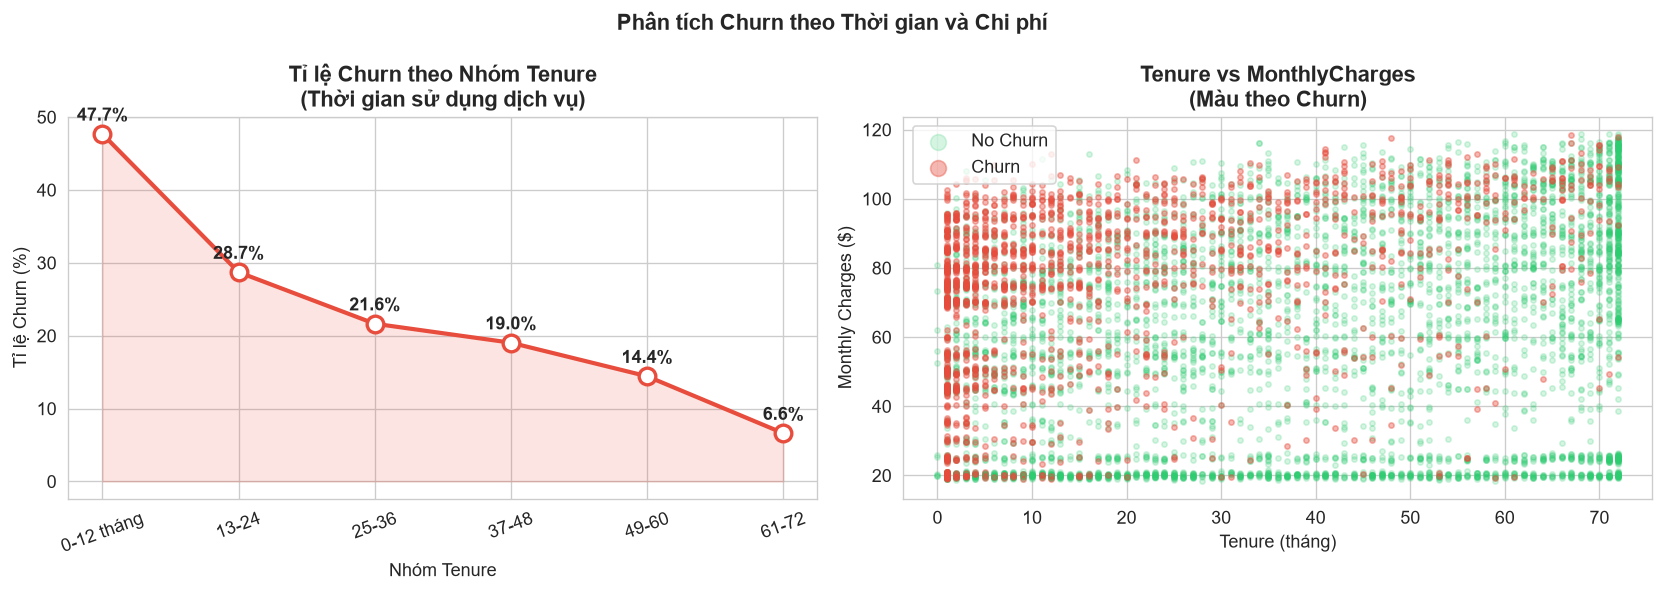

In [15]:
# ============================================================
# TỈ LỆ CHURN THEO TENURE (biểu đồ đường)
# ============================================================
df_temp['tenure_group'] = pd.cut(df_temp['tenure'], 
                                  bins=[0, 12, 24, 36, 48, 60, 72],
                                  labels=['0-12 tháng', '13-24', '25-36', '37-48', '49-60', '61-72'])

churn_by_tenure = df_temp.groupby('tenure_group', observed=True)['Churn'].apply(
    lambda x: (x == 'Yes').sum() / len(x) * 100
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(churn_by_tenure.index.astype(str), churn_by_tenure.values, 
             marker='o', markersize=10, linewidth=2.5, color='#e74c3c', markerfacecolor='white', markeredgewidth=2)
axes[0].fill_between(range(len(churn_by_tenure)), churn_by_tenure.values, alpha=0.15, color='#e74c3c')
axes[0].set_title('Tỉ lệ Churn theo Nhóm Tenure\n(Thời gian sử dụng dịch vụ)', fontweight='bold')
axes[0].set_ylabel('Tỉ lệ Churn (%)')
axes[0].set_xlabel('Nhóm Tenure')
axes[0].tick_params(axis='x', rotation=20)
for x, y in enumerate(churn_by_tenure.values):
    axes[0].annotate(f'{y:.1f}%', (x, y), textcoords='offset points', 
                     xytext=(0, 8), ha='center', fontweight='bold')

# Scatter: MonthlyCharges vs tenure, màu theo churn
churn_yes = df_temp[df_temp['Churn'] == 'Yes']
churn_no = df_temp[df_temp['Churn'] == 'No']
axes[1].scatter(churn_no['tenure'], churn_no['MonthlyCharges'], 
                alpha=0.2, c='#2ecc71', s=10, label='No Churn')
axes[1].scatter(churn_yes['tenure'], churn_yes['MonthlyCharges'], 
                alpha=0.4, c='#e74c3c', s=10, label='Churn')
axes[1].set_title('Tenure vs MonthlyCharges\n(Màu theo Churn)', fontweight='bold')
axes[1].set_xlabel('Tenure (tháng)')
axes[1].set_ylabel('Monthly Charges ($)')
axes[1].legend(markerscale=3)

plt.suptitle('Phân tích Churn theo Thời gian và Chi phí', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/05_churn_tenure_charges.png', bbox_inches='tight', dpi=150)
plt.show()

---
## 7. Correlation Analysis

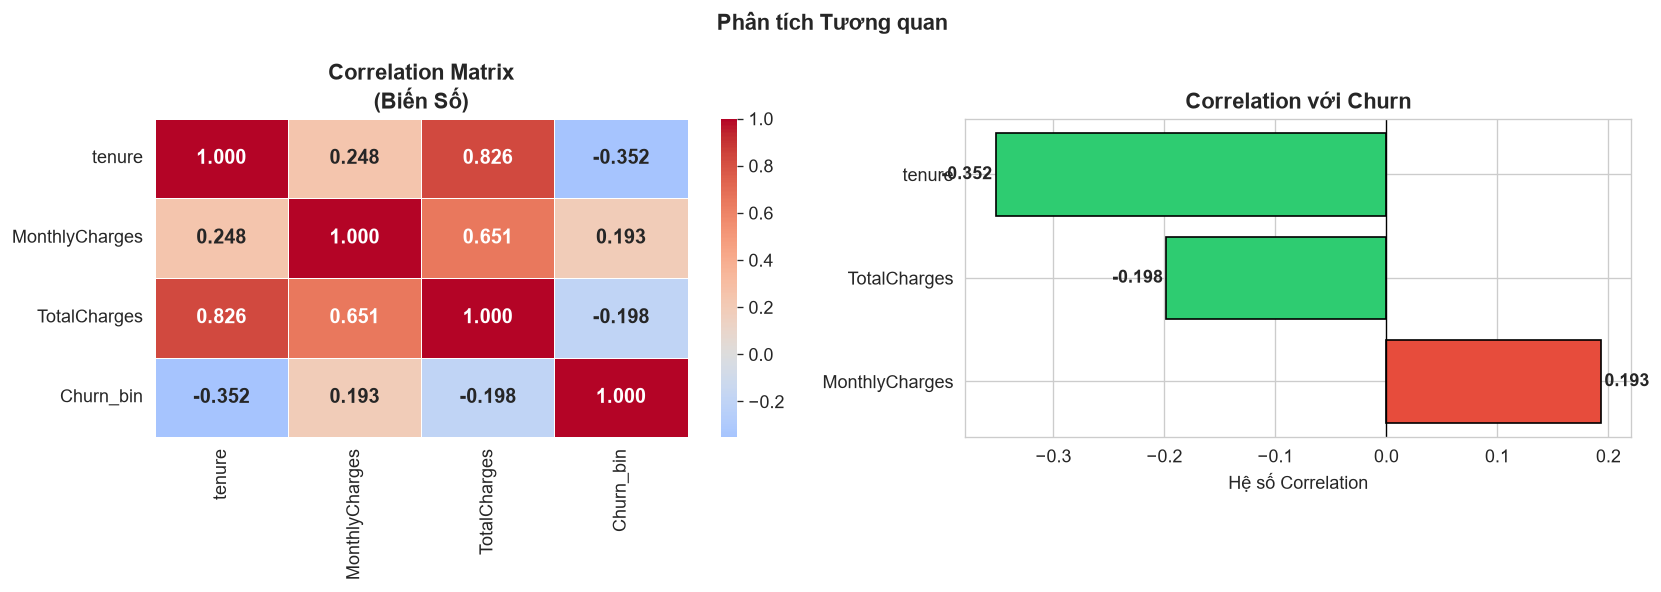

In [16]:
# ============================================================
# CORRELATION HEATMAP (chỉ biến số)
# ============================================================
# Encode nhanh để tính correlation
df_corr = df_temp.copy()
df_corr['Churn_bin'] = (df_corr['Churn'] == 'Yes').astype(int)

corr_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn_bin']
corr_matrix = df_corr[corr_cols].corr()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Full correlation heatmap
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', 
            center=0, ax=axes[0], linewidths=0.5,
            annot_kws={'size': 12, 'weight': 'bold'})
axes[0].set_title('Correlation Matrix\n(Biến Số)', fontweight='bold')

# Correlation với Churn (bar chart)
corr_with_churn = corr_matrix['Churn_bin'].drop('Churn_bin').sort_values(key=abs, ascending=True)
colors_corr = ['#e74c3c' if v > 0 else '#2ecc71' for v in corr_with_churn.values]
axes[1].barh(corr_with_churn.index, corr_with_churn.values, color=colors_corr, edgecolor='black')
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Correlation với Churn', fontweight='bold')
axes[1].set_xlabel('Hệ số Correlation')
for i, v in enumerate(corr_with_churn.values):
    axes[1].text(v + 0.003 if v >= 0 else v - 0.003, i, 
                f'{v:.3f}', va='center', fontweight='bold',
                ha='left' if v >= 0 else 'right')

plt.suptitle('Phân tích Tương quan', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/06_correlation.png', bbox_inches='tight', dpi=150)
plt.show()

---
## 8. Tổng kết EDA – Key Insights

Chạy cell dưới để in ra các phát hiện quan trọng từ EDA.

In [17]:
# ============================================================
# TỔNG KẾT KEY INSIGHTS
# ============================================================
print('=' * 60)
print('          TỔNG KẾT EDA – KEY INSIGHTS')
print('=' * 60)

avg_churn = df['Churn'].eq('Yes').mean() * 100

print(f'\n📌 Tỉ lệ Churn trung bình: {avg_churn:.1f}%')
print(f'   → Tập dữ liệu MẤT CÂN BẰNG (imbalanced)')

# Churn theo Contract
c_contract = df.groupby('Contract')['Churn'].apply(lambda x: (x=='Yes').mean()*100)
print(f'\n📌 Churn theo Hợp đồng (Contract):')
for idx, val in c_contract.items():
    marker = '🔴' if val > avg_churn else '🟢'
    print(f'   {marker} {idx}: {val:.1f}%')

# Churn theo InternetService
c_internet = df.groupby('InternetService')['Churn'].apply(lambda x: (x=='Yes').mean()*100)
print(f'\n📌 Churn theo Dịch vụ Internet:')
for idx, val in c_internet.items():
    marker = '🔴' if val > avg_churn else '🟢'
    print(f'   {marker} {idx}: {val:.1f}%')

# Tenure stats
print(f'\n📌 Tenure theo Churn:')
tenure_stats = df_temp.groupby('Churn')['tenure'].mean()
for idx, val in tenure_stats.items():
    print(f'   {idx}: {val:.1f} tháng trung bình')

print(f'\n📌 MonthlyCharges theo Churn:')
charges_stats = df_temp.groupby('Churn')['MonthlyCharges'].mean()
for idx, val in charges_stats.items():
    print(f'   {idx}: ${val:.2f}/tháng trung bình')

print()
print('=' * 60)
print('🔑 NHÓM KHÁCH HÀNG CÓ NGUY CƠ CHURN CAO:')
print('   ✗ Hợp đồng Month-to-month')
print('   ✗ Dùng Fiber optic')
print('   ✗ Tenure ngắn (mới dùng dịch vụ)')
print('   ✗ Monthly Charges cao')
print('   ✗ Không có Online Security / Tech Support')
print()
print('✅ Sẵn sàng chuyển sang Notebook 2: Data Cleaning!')
print('=' * 60)

          TỔNG KẾT EDA – KEY INSIGHTS

📌 Tỉ lệ Churn trung bình: 26.5%
   → Tập dữ liệu MẤT CÂN BẰNG (imbalanced)

📌 Churn theo Hợp đồng (Contract):
   🔴 Month-to-month: 42.7%
   🟢 One year: 11.3%
   🟢 Two year: 2.8%

📌 Churn theo Dịch vụ Internet:
   🟢 DSL: 19.0%
   🔴 Fiber optic: 41.9%
   🟢 No: 7.4%

📌 Tenure theo Churn:
   No: 37.6 tháng trung bình
   Yes: 18.0 tháng trung bình

📌 MonthlyCharges theo Churn:
   No: $61.27/tháng trung bình
   Yes: $74.44/tháng trung bình

🔑 NHÓM KHÁCH HÀNG CÓ NGUY CƠ CHURN CAO:
   ✗ Hợp đồng Month-to-month
   ✗ Dùng Fiber optic
   ✗ Tenure ngắn (mới dùng dịch vụ)
   ✗ Monthly Charges cao
   ✗ Không có Online Security / Tech Support

✅ Sẵn sàng chuyển sang Notebook 2: Data Cleaning!
